Connected to .venv01 (3.13.11) (Python 3.13.11)

In [ ]:
# SEARCH WORDS :
# FINAL_READY_OUTPUTS_BY_YEAR
# YEARLY_TCN_ESTIMATION
# YEARLY_MFIV_GARCH_ESTIMATION
# TESTING_MAIN_WITH_CACHE
# TCN_SCORE_CALIBRATION_DIAGNOSTIC
## TCN_SCORE_THRESHOLD_CALIBRATION
### TCN_SCORE_THRESHOLD_TRADER_CALIBRATION
import pandas as pd
import numpy as np
from math import sqrt, pi, exp
from arch import arch_model
import yfinance as yf 
from scipy.optimize import minimize
import warnings
from arch.__future__ import reindexing
from arch.utility.exceptions import ConvergenceWarning
# from srcA.msGarch import msGARCH
# from srcA.metrics import metrics
# from srcA.msGarch import msGARCHIV
from tqdm import tqdm

from xgboost import XGBRegressor
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message="y is poorly scaled")
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)


import os, sys
sys.path.insert(0, "/Users/shah/CODE_BOOK_4/THESIS_WORKING/THESIS_2")
sys.path.insert(0, "/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/MFIV_calibration")
os.chdir("/Users/shah/CODE_BOOK_4/THESIS_WORKING/THESIS_2")
sys.modules.pop("srcB", None)

### NOTE :
# # COMES FROM MODELLING.ipynb
import pickle 
with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/outputs_by_year/outputs_by_year_01.pkl", "rb") as f:
    outputs_by_year = pickle.load(f)


# IMPORTS FROM SRC
from srcB.market import *
from srcB.trader_testing import testing_execute_trading_strategy
from srcB.helpers import *

# READ D_BTC AND DF
from pathlib import Path
DATA_DIR = Path("../data/rawData")
YEARS = [2019, 2020, 2021]
d_btc_raw_by_year = {}
df_raw_by_year = {}
for y in YEARS:
    d_btc_raw_by_year[y] = pd.read_parquet(DATA_DIR / f"btc_underlying_minutely_{y}.parquet")
    df_raw_by_year[y]    = pd.read_parquet(DATA_DIR / f"derivative_data_{y}.parquet")

# SET INDEX TO DATETIME
for y in YEARS:
    d_btc_raw_by_year[y] = d_btc_raw_by_year[y].set_index(pd.to_datetime(d_btc_raw_by_year[y]["date_time"]))
    df_raw_by_year[y] = df_raw_by_year[y].set_index(pd.to_datetime(df_raw_by_year[y]["date_time"]))


# ==================================================================================================================
# ======================================= LOAD XQ_BY_YEAR USING X_BY_YEAR ==========================================
# ==================================================================================================================

with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/x_by_year_fut/x_by_year.pkl", "rb") as f:
    X_by_year = pd.read_pickle(f)

YEARS = [2019, 2020, 2021]
QUARTERS = ["q1", "q2", "q3", "q4"]

for y in YEARS:
    X_by_year[y] = X_by_year[y].copy()
    X_by_year[y]["rv"] = X_by_year[y]["rt"] ** 2

Xq_by_year = {}

for y in YEARS:
    Xq_by_year[y] = {}

    Xq_by_year[y]["q1"] = X_by_year[y].loc[f"{y}-01-01" : f"{y}-03-31 23:59:59"].copy()

    Xq_by_year[y]["q2"] = X_by_year[y].loc[f"{y}-04-01" : f"{y}-06-30 23:59:59"].copy()

    Xq_by_year[y]["q3"] = X_by_year[y].loc[f"{y}-07-01" : f"{y}-09-30 23:59:59"].copy()

    Xq_by_year[y]["q4"] = X_by_year[y].loc[f"{y}-10-01" : f"{y}-12-31 23:59:59"].copy()


# ==================================================================================================================
# ======================================= MFIV SCALING =============================================================
# ================== CONVERT ANNUALIZED MFIV -> CUMULATIVE H-HOUR DECIMAL VARIANCE ===============================
# ==================================================================================================================

MFIVS = list(range(2, 577))

for y in YEARS:
    for q in QUARTERS:
        for H in MFIVS:
            Xq_by_year[y][q][f"MFIV_{H}"] *= H / 8760.0


# ==================================================================================================================
# ============================================= BORROW RFR COLUMN  =================================================
# ==================================================================================================================
import pickle
with open ("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/ready_data/d_btc_by_year_all.pkl", "rb") as f :
    d_btc_by_year = pickle.load(f)

YEARS = [2019, 2020, 2021]
for y in YEARS:
    d_btc_raw_by_year[y]["rfr"] = d_btc_by_year[y]["rfr"].reindex(d_btc_raw_by_year[y].index, method="ffill")

# =============================================================================================================
# ======================================= CHECKPOINT 1. RUN UNTIL HERE ========================================
# =============================================================================================================








# # =============================== LOAD OPTIMAL PARAMETERS IN hyperparam_tuning.py ==================================
with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/hyperparameters/tcn_best_params.pkl", "rb") as f:
    best_tcn_params = pickle.load(f)

In [ ]:
# # ======================================= YEARLY_TCN_ESTIMATION  ===================================================
# # ==================================================================================================================
sys.modules.pop("srcB.tcn_model_mfiv", None)
from srcB.tcn_model_mfiv import *

YEARS = [2019, 2020, 2021]
QUARTERS = ["q1", "q2", "q3", "q4"]
tcn_bundle_by_year = {}
tcn_targets_by_year = {}
tcn_output_by_year = {}

for y in YEARS:
    X_df = pd.concat([
        Xq_by_year[y][q]
        for q in QUARTERS
    ]).sort_index().copy()

    garch_df = pd.concat([
        outputs_by_year[y][q]["garch"]
        for q in QUARTERS
    ]).sort_index()

    X_df["garch"] = garch_df.reindex(X_df.index)

    tcn_output, tcn_bundle, tcn_targets = tcn_mfiv(
        X_df=X_df,
        option_df=df_raw_by_year[y],
        time_df=d_btc_raw_by_year[y],
        sequence_length=168,
        forward_hours=24,
        delta_target=0.20,
        channels=best_tcn_params["channels"],
        kernel_size=best_tcn_params["kernel_size"],
        dropout=best_tcn_params["dropout"],
        epochs=best_tcn_params["epochs_by_year"][y],
        batch_size=best_tcn_params["batch_size"],
        learning_rate=best_tcn_params["learning_rate"],
        weight_decay=best_tcn_params["weight_decay"]
    )
    tcn_output_by_year[y] = tcn_output
    tcn_bundle_by_year[y] = tcn_bundle
    tcn_targets_by_year[y] = tcn_targets

    for q in QUARTERS:
        q_index = Xq_by_year[y][q].index
        tcn_q = tcn_output.reindex(q_index)
        outputs_by_year[y][q] = pd.concat( [outputs_by_year[y][q], tcn_q], axis=1 )

In [ ]:
# =============================================================================================================
# ======================================= SAVE TCN BUNDLES ====================================================
# =============================================================================================================
os.makedirs("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/TCN", exist_ok = True)
import pickle
with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/TCN/tcn_bundle_by_year.pkl", "wb") as f:
    pickle.dump(tcn_bundle_by_year, f)

print("TCN bundles saved:", list(tcn_bundle_by_year.keys()))

# # ==================================================================================================================
# SAVE THIS OUTPUTS
with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/outputs_by_year/outputs_by_year_04.pkl", "wb") as f:
    pickle.dump(outputs_by_year, f)

TCN bundles saved: [2019, 2020, 2021]


In [ ]:
from srcB.market import *
from srcB.trader_testing import testing_execute_trading_strategy
from srcB.helpers import *

In [ ]:
# ==================================================================================================================
# ======================================= PREPARE TRADER INPUT ======================================================
# ==================================================================================================================

for y in YEARS:
    for q in QUARTERS:
        outputs_by_year[y][q]["rv"] = Xq_by_year[y][q]["rv"].reindex(
            outputs_by_year[y][q].index
        )
        outputs_by_year[y][q]["MFIV_24"] = Xq_by_year[y][q]["MFIV_24"].reindex(
            outputs_by_year[y][q].index
        )

# ==================================================================================================================
# ======================================= CACHE FOR WARMUP ==========================================================
# ==================================================================================================================
CACHE_YEARS = [2019, 2020, 2021]
RUN_BY = "year"
if RUN_BY == "year":
    trader_cache = {
        y: pd.concat(
            [
                outputs_by_year[yy][q]
                for yy in CACHE_YEARS
                if yy <= y
                for q in QUARTERS
            ]
        ).sort_index()
        for y in CACHE_YEARS
    }

elif RUN_BY == "quarter":
    trader_cache = {
        (y, q): pd.concat(
            [
                outputs_by_year[yy][qq]
                for yy in CACHE_YEARS
                for qq in QUARTERS
                if (
                    yy < y
                    or (yy == y and QUARTERS.index(qq) <= QUARTERS.index(q))
                )
            ]
        ).sort_index()
        for y in CACHE_YEARS
        for q in QUARTERS
    }
if RUN_BY == "year":
    PERIODS = YEARS
else:
    PERIODS = [(y, q) for y in YEARS for q in QUARTERS]
    

# ==================================================================================================================
# ======================================= TESTING_MAIN_WITH_CACHE  ==========================================================
# ==================================================================================================================
# sys.modules.pop("srcB", None)

sys.modules.pop("srcB.trader_testing_tcn", None)
from srcB.trader_testing_tcn import testing_execute_trading_strategy
YEARS = [2019, 2020, 2021]
MODELS = [
    "tcn_mfiv"
]
RUN_BY = "year"
strategy_results = {}
for YEAR in YEARS:
    for MODEL in MODELS:
        market = Market(
            option_df=df_raw_by_year[YEAR],
            time_df=d_btc_raw_by_year[YEAR],
            starting_cash=100_000,
            im_multiplier=0.15,
            mm_buffer_rate=0.05,
        )
        greek_tests = []
        yearly_snapshots = []
        if RUN_BY == "year":
            periods = [None]
        else:
            periods = ["q1", "q2", "q3", "q4"]
            
        for q in periods:
            snapshots, greek_tests_q = testing_execute_trading_strategy(
                bt_year=YEAR,
                bt_quarter=q,
                model=MODEL,
                outputs_by_year=outputs_by_year,
                market=market,
                trader_cache=trader_cache,
                run_by=RUN_BY,
                quantity=10,
                expiry_days=30,
                hold_days=7,
                lookback_hours=168,
                mean_hours=12,
                ql=0.10,
                qh=0.90,
                z=1.645
            )

            greek_tests.extend(greek_tests_q)
            yearly_snapshots.extend(snapshots)
        history_key = f"{MODEL}_{str(YEAR)[2:]}"
        equity_curve = market.get_equity_history()
        strategy_results[history_key] = {
            "equity_curve": equity_curve,
            "snapshots": yearly_snapshots,
            "greek_tests": greek_tests,
            "orders": list(market.orders),
            "transactions": list(market.transactions),
            "final_cash": market.cash,
            "required_margin": market.get_total_required_margin(),
            "free_liquidity": market.get_free_liquidity(),
        }
print(YEAR, MODEL)

2021 tcn_mfiv


In [ ]:
# ==================================================================================================================
print(len(greek_tests))
print(greek_tests[:1])
print(pd.Series([x["action"] for x in market.transactions]).value_counts())
print("outputs:", "tcn_action" in outputs_by_year[2019]["q1"].columns)
print("cache:", "tcn_action" in trader_cache[2019].columns)
[c for c in trader_cache[2019].columns if c.startswith("tcn")]

277
[{'time': Timestamp('2021-01-13 02:00:00+0000', tz='UTC'), 'tcn_action': 'short_straddle', 'tcn_best_score': 0.005718857049942017, 'signal': nan, 'q_lo': nan, 'selected_calls': [<srcB.market.Instrument object at 0x15df0f6d0>], 'selected_puts': [<srcB.market.Instrument object at 0x15688bbd0>], 'call_ivs': [141.52], 'put_ivs': [129.17], 'spot': 33231.5, 'rfr': 0.0008997975607295042, 'call_greeks': [{'delta': -0.43187154433950425, 'gamma': np.float64(-0.00011535073167516373)}], 'put_greeks': [{'delta': 0.5782413286988961, 'gamma': np.float64(-0.00012577965014022816)}], 'entry_equity': np.float64(101679.9285097682)}]
sell_to_open         406
buy_to_close         277
expiry_settlement    163
buy_to_open          148
sell_to_close        114
Name: count, dtype: int64
outputs: True
cache: True


['tcn_long_straddle',
 'tcn_short_straddle',
 'tcn_long_strangle',
 'tcn_short_strangle',
 'tcn_best_score',
 'tcn_action']

In [ ]:
# ==================================================================================================================
# ============================================= SAVE DICT  ========================================================
# ==================================================================================================================
import sys, os
os.makedirs("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/data_strategy_results", exist_ok = True)
import pickle 
with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/data_strategy_results/strategy_results.pkl", "wb") as f:
    pickle.dump(strategy_results, f)

In [ ]:
## ==================================================================================================================
## ============================================= SHARPEE  ===========================================================
## ==================================================================================================================
YEARS = [2019, 2020, 2021]
MODELS = [
    # "garch",
    # "garch_n_mfiv",
    "tcn_mfiv"
]
rows = []

for y in YEARS:
    for model in MODELS:

        history_key = f"{model}_{str(y)[2:]}"
        snapshots = strategy_results[history_key]["snapshots"]

        equity = pd.Series( [s["equity"] for s in snapshots], index=[s["time"] for s in snapshots] )

        returns = equity.pct_change().dropna()
        sharpe = returns.mean() / returns.std() * np.sqrt(24 * 365)

        rows.append({ "year": y, "model": model, "sharpe": sharpe })

sharpe_table = pd.DataFrame(rows)

print(sharpe_table)

   year     model    sharpe
0  2019  tcn_mfiv -0.276879
1  2020  tcn_mfiv  0.397966
2  2021  tcn_mfiv  1.216888


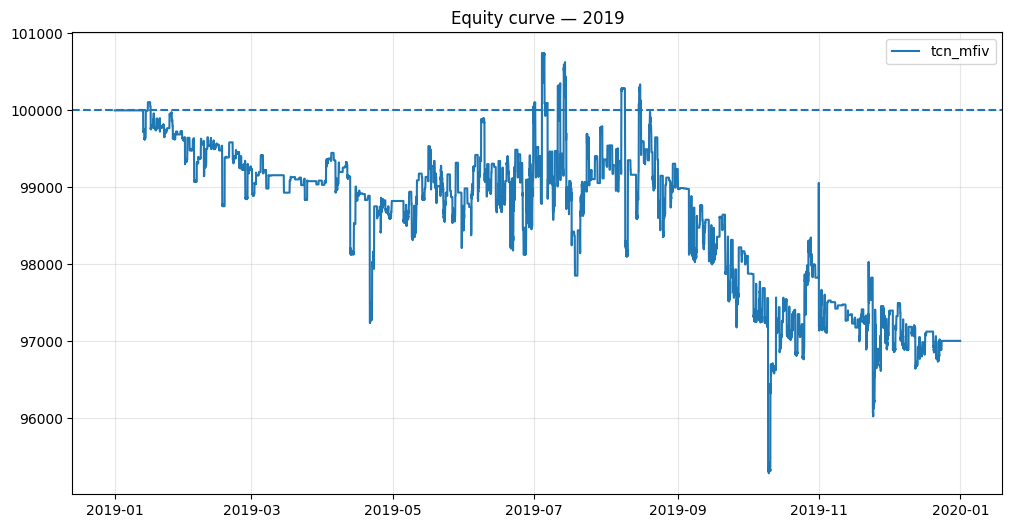

In [ ]:
# ==================================================================================================================
# ============================================= PLOT EQUITY  =======================================================
# ==================================================================================================================
import matplotlib.pyplot as plt
# MODELS = ["garch", "garch_mfiv", "garch_n_mfiv", "garch_mfiv_avg", "regime_switching_mfiv"]
MODELS = [
    "tcn_mfiv"
]
PLOT_YEAR = 2019
plt.figure(figsize=(12, 6))
for MODEL in MODELS:
    plot_key = f"{MODEL}_{str(PLOT_YEAR)[2:]}"
    result = strategy_results[plot_key]
    eq = pd.DataFrame(result["snapshots"]).drop_duplicates("time").sort_values("time")
    plt.plot(eq["time"], eq["equity"], label=MODEL)
plt.axhline(100_000, linestyle="--")
plt.title(f"Equity curve — {PLOT_YEAR}")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [ ]:
# ========================================================================================================================================
# ========================================== ALL STRATEGY DIAGNOSTICS  ===================================================================
# ========================================================================================================================================
# position_side = "long_straddle"
position_side = "short_strangle"
all_groups = []
for y in YEARS:
    for the_model in MODELS:
        tx = pd.DataFrame(strategy_results[f"{the_model}_{str(y)[2:]}"]["transactions"]).sort_values("time")
        open_actions = {"buy_to_open", "sell_to_open"}
        close_actions = {"buy_to_close", "sell_to_close", "liquidate", "expiry_settlement"}
        trades = []
        open_pos = {}
        for _, r in tx.iterrows():
            sym = r["symbol"]
            if r["action"] in open_actions:
                open_pos[sym] = {
                    "entry_time": r["time"],
                    "right": r["right"],
                    "direction": r["held_direction"],
                    "pnl": float(r["cash_change"])
                }
            elif r["action"] in close_actions and sym in open_pos:
                open_pos[sym]["pnl"] += float(r["cash_change"])
                open_pos[sym]["exit_time"] = r["time"]

                trades.append({
                    "symbol": sym,
                    **open_pos.pop(sym)
                })
        legs = pd.DataFrame(trades)
        for entry_time, g in legs.groupby("entry_time"):
            side = (
                "short_strangle"
                if (g["direction"] == "sell").all()
                else "long_straddle"
            )
            if side != position_side:
                continue
            call_pnl = g.loc[g["right"] == "C", "pnl"].sum()
            put_pnl = g.loc[g["right"] == "P", "pnl"].sum()
            all_groups.append({
                "year": y,
                "model": the_model,
                "entry": entry_time,
                "exit": g["exit_time"].max(),
                "side": side,
                "call_pnl": call_pnl,
                "put_pnl": put_pnl,
                "total_pnl": call_pnl + put_pnl,
                "call_result": "PROFIT" if call_pnl > 0 else "LOSS",
                "put_result": "PROFIT" if put_pnl > 0 else "LOSS" if put_pnl < 0 else "FLAT",
                "position_result": "PROFIT" if call_pnl + put_pnl > 0 else "LOSS"
            })
result_all = pd.DataFrame(all_groups)
print(result_all.to_string(index=False))
summary = (
    result_all.groupby(["year", "model"])
    .agg(
        positions=("total_pnl", "size"),
        profitable=("total_pnl", lambda x: (x > 0).sum()),
        losing=("total_pnl", lambda x: (x < 0).sum()),
        total_pnl=("total_pnl", "sum"),
        call_profit=("call_pnl", lambda x: (x > 0).sum()),
        call_loss=("call_pnl", lambda x: (x < 0).sum()),
        put_profit=("put_pnl", lambda x: (x > 0).sum()),
        put_loss=("put_pnl", lambda x: (x < 0).sum())
    )
    .reset_index()
)
print("\nSUMMARY")
print(summary.to_string(index=False))

 year    model                     entry                      exit           side     call_pnl      put_pnl    total_pnl call_result put_result position_result
 2019 tcn_mfiv 2019-01-15 07:00:00+00:00 2019-01-16 12:00:00+00:00 short_strangle     9.126480    -4.778000     4.348480      PROFIT       LOSS          PROFIT
 2019 tcn_mfiv 2019-01-24 15:00:00+00:00 2019-01-25 22:00:00+00:00 short_strangle    13.566230    11.876815    25.443045      PROFIT     PROFIT          PROFIT
 2019 tcn_mfiv 2019-03-05 00:00:00+00:00 2019-03-06 00:00:00+00:00 short_strangle   -54.586255    37.340450   -17.245805        LOSS     PROFIT            LOSS
 2019 tcn_mfiv 2019-03-06 07:00:00+00:00 2019-03-07 08:00:00+00:00 short_strangle     7.110055     4.557570    11.667625      PROFIT     PROFIT          PROFIT
 2019 tcn_mfiv 2019-04-03 02:00:00+00:00 2019-04-04 10:00:00+00:00 short_strangle    24.933950     1.548711    26.482661      PROFIT     PROFIT          PROFIT
 2019 tcn_mfiv 2019-04-04 11:00:00+00:00

In [ ]:
# ========================================================================================================================================
# ========================================== TCN SPECIFIC (TRADER DIAGNOSTICS)============================================
# ========================================================================================================================================
# This block reconstructs the actual executed TCN option positions from the trader transaction log and summarizes how each TCN strategy type performed.
MODEL = "tcn_mfiv"
all_trades = []
for y in YEARS:
    tx = pd.DataFrame(strategy_results[f"{MODEL}_{str(y)[2:]}"]["transactions"]).sort_values("time")

    open_actions = {"buy_to_open", "sell_to_open"}
    close_actions = {"buy_to_close", "sell_to_close", "liquidate", "expiry_settlement"}

    trades = []
    open_pos = {}

    for _, r in tx.iterrows():
        sym = r["symbol"]
        if r["action"] in open_actions:
            open_pos[sym] = {
                "entry_time": r["time"],
                "right": r["right"],
                "strike": r["strike"],
                "direction": r["held_direction"],
                "pnl": float(r["cash_change"])
            }

        elif r["action"] in close_actions and sym in open_pos:
            open_pos[sym]["pnl"] += float(r["cash_change"])
            open_pos[sym]["exit_time"] = r["time"]
            trades.append({
                "symbol": sym,
                **open_pos.pop(sym)
            })

    legs = pd.DataFrame(trades)
    for entry_time, g in legs.groupby("entry_time"):
        direction = "short" if (g["direction"] == "sell").all() else "long"
        structure = "straddle" if g["strike"].nunique() == 1 else "strangle"
        side = f"{direction}_{structure}"
        call_pnl = g.loc[g["right"] == "C", "pnl"].sum()
        put_pnl = g.loc[g["right"] == "P", "pnl"].sum()
        total_pnl = call_pnl + put_pnl

        all_trades.append({
            "year": y,
            "entry": entry_time,
            "exit": g["exit_time"].max(),
            "side": side,
            "call_pnl": call_pnl,
            "put_pnl": put_pnl,
            "total_pnl": total_pnl,
            "position_result": "PROFIT" if total_pnl > 0 else "LOSS"
        })

tcn_trades = pd.DataFrame(all_trades)
print(tcn_trades.to_string(index=False))

summary = (
    tcn_trades.groupby(["year", "side"])
    .agg(
        positions=("total_pnl", "size"),
        profitable=("total_pnl", lambda x: (x > 0).sum()),
        losing=("total_pnl", lambda x: (x < 0).sum()),
        total_pnl=("total_pnl", "sum"),
        avg_pnl=("total_pnl", "mean")
    )
    .reset_index()
)
print("\nSUMMARY")
print(summary.to_string(index=False))

 year                     entry                      exit           side     call_pnl      put_pnl    total_pnl position_result
 2019 2019-01-13 07:00:00+00:00 2019-01-14 09:00:00+00:00  long_straddle   -44.206635    39.167470    -5.039165            LOSS
 2019 2019-01-15 07:00:00+00:00 2019-01-16 12:00:00+00:00 short_strangle     9.126480    -4.778000     4.348480          PROFIT
 2019 2019-01-16 13:00:00+00:00 2019-01-17 17:00:00+00:00  long_straddle   -37.810250    -1.558275   -39.368525            LOSS
 2019 2019-01-17 23:00:00+00:00 2019-01-18 23:00:00+00:00  long_straddle   -48.775675   -17.495340   -66.271015            LOSS
 2019 2019-01-19 10:00:00+00:00 2019-01-20 11:00:00+00:00  long_straddle    12.383470    -6.350995     6.032475          PROFIT
 2019 2019-01-20 12:00:00+00:00 2019-01-22 01:00:00+00:00  long_straddle    -5.515105   -80.328570   -85.843675            LOSS
 2019 2019-01-22 06:00:00+00:00 2019-01-23 14:00:00+00:00  long_straddle    -8.092365   -36.900680   -44

In [ ]:
# # ============================================= PHASE 2 =====================================================
# # ======================================= DIAGNOSTICS FOR TCN ===============================================
# # ===========================================================================================================
## =============================================================================================================
## =========================== TCN TARGET PERFORMANCE: EXECUTED VS SKIPPED =====================================

# In every year the executed subset has lower target Sharpe than the skipped subset, most clearly in 2021.
# Therefore trader path dependence is again selecting only a small and weaker subset of the model's available opportunities.

# However, action_match is only 0.41, 0.65, and 0.75 here, unlike the exact action matching established in the MFIV analysis.
# This reconstruction from transaction-level side labels should therefore not yet be treated as the definitive execution diagnostic.
# The following greek_tests-based execution check is the important one for verifying the actual TCN action at entry.
# =============================================================================================================
# =========================== TCN TARGET PERFORMANCE: EXECUTED VS SKIPPED =====================================
# =============================================================================================================

target_cols = [
    "target_long_straddle",
    "target_short_straddle",
    "target_long_strangle",
    "target_short_strangle"
]
rows = []
for y in YEARS:
    test = pd.concat([
        tcn_output_by_year[y][["tcn_action"]],
        tcn_targets_by_year[y][target_cols]
    ], axis=1, sort=False).dropna()
    test = test[test["tcn_action"] != "no_trade"].copy()
    test["target_pnl"] = 0.0
    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        m = test["tcn_action"] == action
        test.loc[m, "target_pnl"] = test.loc[m, f"target_{action}"]
    entries = tcn_trades[tcn_trades["year"] == y][["entry", "side"]].copy()
    entries["entry"] = pd.to_datetime(entries["entry"], utc=True).dt.floor("h")
    executed = test[test.index.isin(entries["entry"])]
    skipped = test[~test.index.isin(entries["entry"])]
    action_at_entry = test["tcn_action"].reindex(entries["entry"]).to_numpy()
    action_match = (action_at_entry == entries["side"].to_numpy()).mean()
    rows.append({
        "year": y,
        "signals": len(test),
        "executed": len(executed),
        "execution_rate": len(executed) / len(test),
        "action_match": action_match,
        "all_sharpe": test["target_pnl"].mean() / test["target_pnl"].std(),
        "executed_sharpe": executed["target_pnl"].mean() / executed["target_pnl"].std(),
        "skipped_sharpe": skipped["target_pnl"].mean() / skipped["target_pnl"].std()
    })
execution_check = pd.DataFrame(rows)
print(execution_check)


# =========================== REQUIRES STRATEGY_RESULTS =======================================================
# =========================== TCN TARGET PERFORMANCE: EXECUTED VS SKIPPED =====================================
# =============================================================================================================

target_cols = [
    "target_long_straddle",
    "target_short_straddle",
    "target_long_strangle",
    "target_short_strangle"
]

rows = []

for y in YEARS:

    test = pd.concat([
        tcn_output_by_year[y][["tcn_action"]],
        tcn_targets_by_year[y][target_cols]
    ], axis=1, sort=False).dropna()

    test = test[test["tcn_action"] != "no_trade"].copy()

    test["target_pnl"] = 0.0

    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        m = test["tcn_action"] == action
        test.loc[m, "target_pnl"] = test.loc[m, f"target_{action}"]

    entries = pd.DataFrame(
        strategy_results[f"tcn_mfiv_{str(y)[2:]}"]["greek_tests"]
    )

    entries["time"] = pd.to_datetime(entries["time"], utc=True).dt.floor("h")
    entries = entries.drop_duplicates("time")

    covered = entries[entries["time"].isin(test.index)].copy()

    predicted = test["tcn_action"].reindex(covered["time"]).to_numpy()
    action_match = (predicted == covered["tcn_action"].to_numpy()).mean()

    executed = test[test.index.isin(covered["time"])]
    skipped = test[~test.index.isin(covered["time"])]

    rows.append({
        "year": y,
        "signals": len(test),
        "successful_entries": len(entries),
        "entries_with_target": len(covered),
        "target_coverage": len(covered) / len(entries),
        "action_match": action_match,
        "all_sharpe": test["target_pnl"].mean() / test["target_pnl"].std(),
        "executed_sharpe": executed["target_pnl"].mean() / executed["target_pnl"].std(),
        "skipped_sharpe": skipped["target_pnl"].mean() / skipped["target_pnl"].std()
    })

execution_check = pd.DataFrame(rows)

print(execution_check)
# However, only part of the trader's successful entries can be matched to the fitted target sample,
# with target coverage increasing from 41% in 2019 to 75% in 2021.
# Within the covered sample, the sequential trader executes a weaker subset than the skipped signals in every year,
# with the deterioration especially strong in 2021.
# This is qualitatively similar to the MFIV TCN result: trader path dependence weakens the model-level opportunity set.

# ========Are higher-score bins better? ==============
# ============================= TCN_SCORE_CALIBRATION_DIAGNOSTIC ========================================
# =============================================================================================================
rows = []
for y in YEARS:
    test = pd.concat([
        tcn_output_by_year[y][["tcn_action", "tcn_best_score"]],
        tcn_targets_by_year[y][target_cols]
    ], axis=1, sort=False).dropna()

    test = test[test["tcn_action"] != "no_trade"].copy()
    test["target_pnl"] = 0.0
    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        m = test["tcn_action"] == action
        test.loc[m, "target_pnl"] = test.loc[m, f"target_{action}"]
        
    test["score_bin"] = pd.qcut(
        test["tcn_best_score"],
        5,
        labels=False,
        duplicates="drop"
    )

    x = (
        test.groupby("score_bin")
        .agg(
            n=("target_pnl", "size"),
            mean_score=("tcn_best_score", "mean"),
            mean_target=("target_pnl", "mean"),
            sharpe=("target_pnl", lambda z: z.mean() / z.std()),
            profitable=("target_pnl", lambda z: (z > 0).mean())
        )
        .reset_index()
    )

    x["year"] = y
    rows.append(x)

score_check = pd.concat(rows, ignore_index=True)

print(score_check[[
    "year", "score_bin", "n", "mean_score",
    "mean_target", "sharpe", "profitable"
]].to_string(index=False))

# The relationship is not perfectly monotonic in the lower score bins, but the highest-score bin has the best realized Sharpe in every year.
# The upper score bins are especially well separated in 2019 and 2021.

# # ===If I only retain signals with tcn_best_score >= threshold, does target-space performance improve? ========
# # ================================= TCN_SCORE_THRESHOLD_CALIBRATION ===========================================
# # =============================================================================================================

tests = {}

for y in YEARS:

    x = pd.concat([
        tcn_output_by_year[y][["tcn_action", "tcn_best_score"]],
        tcn_targets_by_year[y][target_cols]
    ], axis=1, sort=False).dropna()

    x = x[x["tcn_action"] != "no_trade"].copy()
    x["target_pnl"] = 0.0

    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        m = x["tcn_action"] == action
        x.loc[m, "target_pnl"] = x.loc[m, f"target_{action}"]

    tests[y] = x


scores_all = pd.concat([tests[y]["tcn_best_score"] for y in YEARS])

rows = []

for q in [0, .20, .40, .50, .60, .70, .80, .85, .90]:

    threshold = scores_all.quantile(q)

    for y in YEARS:

        x = tests[y][tests[y]["tcn_best_score"] >= threshold]
        sharpe = x["target_pnl"].mean() / x["target_pnl"].std()

        rows.append({
            "quantile": q,
            "threshold": threshold,
            "year": y,
            "n": len(x),
            "mean_target": x["target_pnl"].mean(),
            "sharpe": sharpe
        })

threshold_check = pd.DataFrame(rows)

print(threshold_check.to_string(index=False))

   year  signals  executed  execution_rate  action_match  all_sharpe  \
0  2019     1021        89        0.087169      0.445000    0.169293   
1  2020     2638       172        0.065201      0.725738    0.104564   
2  2021     4151       201        0.048422      0.725632    0.120872   

   executed_sharpe  skipped_sharpe  
0        -0.035230        0.184260  
1         0.059657        0.107202  
2         0.252675        0.115405  
   year  signals  successful_entries  entries_with_target  target_coverage  \
0  2019     1021                 200                   89         0.445000   
1  2020     2638                 237                  172         0.725738   
2  2021     4151                 277                  201         0.725632   

   action_match  all_sharpe  executed_sharpe  skipped_sharpe  
0           1.0    0.169293        -0.035230        0.184260  
1           1.0    0.104564         0.059657        0.107202  
2           1.0    0.120872         0.252675        0.115405 

In [ ]:
# =============================================================================================================
# ================================ TCN SCORE THRESHOLD TRADER CALIBRATION =====================================
# =============================================================================================================

sys.modules.pop("srcB.trader_testing_tcn", None)
from srcB.trader_testing_tcn import testing_execute_trading_strategy

THRESHOLDS = [
    0.0,
    float(scores_all.quantile(.70)),
    float(scores_all.quantile(.80)),
    float(scores_all.quantile(.85)),
    float(scores_all.quantile(.90))
]

rows = []

for threshold in THRESHOLDS:

    for y in YEARS:

        market = Market(
            option_df=df_raw_by_year[y],
            time_df=d_btc_raw_by_year[y],
            starting_cash=100_000,
            im_multiplier=0.15,
            mm_buffer_rate=0.05,
        )

        snapshots, greek_tests = testing_execute_trading_strategy(
            bt_year=y,
            bt_quarter=None,
            model="tcn_mfiv",
            outputs_by_year=outputs_by_year,
            market=market,
            trader_cache=trader_cache,
            run_by="year",
            tcn_score_threshold=threshold,
        )

        equity = pd.Series(
            [s["equity"] for s in snapshots],
            index=[s["time"] for s in snapshots],
        )

        returns = equity.pct_change().dropna()

        sharpe = (
            returns.mean()
            / returns.std()
            * np.sqrt(24 * 365)
        )

        rows.append({
            "threshold": threshold,
            "year": y,
            "trades": len(greek_tests),
            "sharpe": sharpe,
        })


threshold_trader_check = pd.DataFrame(rows)

print(threshold_trader_check.to_string(index=False))

 threshold  year  trades    sharpe
  0.000000  2019     200 -0.276879
  0.000000  2020     237  0.397966
  0.000000  2021     277  1.216888
  0.003118  2019     103  0.079527
  0.003118  2020     151  0.784846
  0.003118  2021     159  0.788620
  0.004154  2019      82  0.080294
  0.004154  2020     116  0.905425
  0.004154  2021     108  0.654273
  0.004862  2019      66  0.423471
  0.004862  2020      93  0.939807
  0.004862  2021      87  0.909850
  0.005913  2019      44  0.300360
  0.005913  2020      53  0.860805
  0.005913  2021      57  0.895657


In [ ]:
# ===== Does the threshold improvement survive the actual sequential trader? =====
# ================================ TCN_SCORE_THRESHOLD_TRADER_CALIBRATION =====================================
# =============================================================================================================

sys.modules.pop("srcB.trader_testing_tcn", None)
from srcB.trader_testing_tcn import testing_execute_trading_strategy

THRESHOLDS = [
    0.0,
    float(scores_all.quantile(.70)),
    float(scores_all.quantile(.80)),
    float(scores_all.quantile(.85)),
    float(scores_all.quantile(.90))
]
rows = []

for threshold in THRESHOLDS:
    for y in YEARS:

        market = Market(
            option_df=df_raw_by_year[y],
            time_df=d_btc_raw_by_year[y],
            starting_cash=100_000,
            im_multiplier=0.15,
            mm_buffer_rate=0.05,
        )

        snapshots, greek_tests = testing_execute_trading_strategy(
            bt_year=y,
            bt_quarter=None,
            model="tcn_mfiv",
            outputs_by_year=outputs_by_year,
            market=market,
            trader_cache=trader_cache,
            run_by="year",
            tcn_score_threshold=threshold
        )

        equity = pd.Series(
            [s["equity"] for s in snapshots],
            index=[s["time"] for s in snapshots]
        )

        returns = equity.pct_change().dropna()
        sharpe = returns.mean() / returns.std() * np.sqrt(24 * 365)

        rows.append({
            "threshold": threshold,
            "year": y,
            "trades": len(greek_tests),
            "sharpe": sharpe
        })

threshold_trader_check = pd.DataFrame(rows)

print(threshold_trader_check.to_string(index=False))

 threshold  year  trades    sharpe
  0.000000  2019     200 -0.276879
  0.000000  2020     237  0.397966
  0.000000  2021     277  1.216888
  0.003118  2019     103  0.079527
  0.003118  2020     151  0.784846
  0.003118  2021     159  0.788620
  0.004154  2019      82  0.080294
  0.004154  2020     116  0.905425
  0.004154  2021     108  0.654273
  0.004862  2019      66  0.423471
  0.004862  2020      93  0.939807
  0.004862  2021      87  0.909850
  0.005913  2019      44  0.300360
  0.005913  2020      53  0.860805
  0.005913  2021      57  0.895657
